# Laboratorio 4 – Segmentación de imágenes con técnicas de agrupación (DermAlpes)

## 0. Importación de librerías y parámetros globales

In [1]:
import os
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:14: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.5.4)
  from scipy.sparse import csr_array, issparse


In [2]:
semilla = 2026           # semilla de K-medias y de la muestra de píxeles para la silueta
lado_max = 128           # lado mayor al que se reduce cada imagen
n_muestra = 2000         # tamaño de la muestra de píxeles para el coeficiente de silueta
rango_k = range(2, 9)    # valores de K a explora
dir_datos = os.path.join('.', 'data')
dir_imgs = os.path.join(dir_datos, 'normal')      # imágenes .jpg
dir_mascaras = os.path.join(dir_datos, 'masks')   # máscaras ISIC

ids_ajuste = ['ISIC_0000085', 'ISIC_0000086', 'ISIC_0000089', 'ISIC_0000094', 'ISIC_0000108',
              'ISIC_0000114', 'ISIC_0000116', 'ISIC_0000122', 'ISIC_0000133', 'ISIC_0000137',
              'ISIC_0000150', 'ISIC_0000153', 'ISIC_0000156', 'ISIC_0000157', 'ISIC_0000112']
len(ids_ajuste)

15

## 1. Pipeline de preparación y representación

### 1.1 Carga de las imágenes

Las imágenes originales miden 2048 × 1536 píxeles. Por eso se reducen a **128 píxeles en el lado mayor**, conservando la proporción. Para esta tarea se va a utilizar la  interpolación por área, la adecuada para reducir tamaño. La reducción pierde detalles finos (pelos, puntos pequeños), lo que es una limitación que se tendrá en cuenta al interpretar resultados. Las máscaras de referencia deberán reducirse al mismo tamaño con vecino más cercano.

In [3]:
def forma_reducida(alto, ancho, lado=lado_max):
    escala = lado / max(alto, ancho)
    return round(alto * escala), round(ancho * escala)


def cargar_imagen(id_img, carpeta=dir_imgs, lado=lado_max):
    bgr = cv2.imread(os.path.join(carpeta, f'{id_img}.jpg'), cv2.IMREAD_COLOR)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    alto, ancho = forma_reducida(*rgb.shape[:2], lado)
    return cv2.resize(rgb, (ancho, alto), interpolation=cv2.INTER_AREA)


imagenes = {id_img: cargar_imagen(id_img) for id_img in ids_ajuste}
pd.Series({id_img: imagen.shape for id_img, imagen in imagenes.items()}, name='forma (alto, ancho, canales)')

ISIC_0000085    (96, 128, 3)
ISIC_0000086    (96, 128, 3)
ISIC_0000089    (96, 128, 3)
ISIC_0000094    (96, 128, 3)
ISIC_0000108    (96, 128, 3)
ISIC_0000114    (96, 128, 3)
ISIC_0000116    (96, 128, 3)
ISIC_0000122    (96, 128, 3)
ISIC_0000133    (96, 128, 3)
ISIC_0000137    (96, 128, 3)
ISIC_0000150    (96, 128, 3)
ISIC_0000153    (96, 128, 3)
ISIC_0000156    (96, 128, 3)
ISIC_0000157    (84, 128, 3)
ISIC_0000112    (96, 128, 3)
Name: forma (alto, ancho, canales), dtype: object

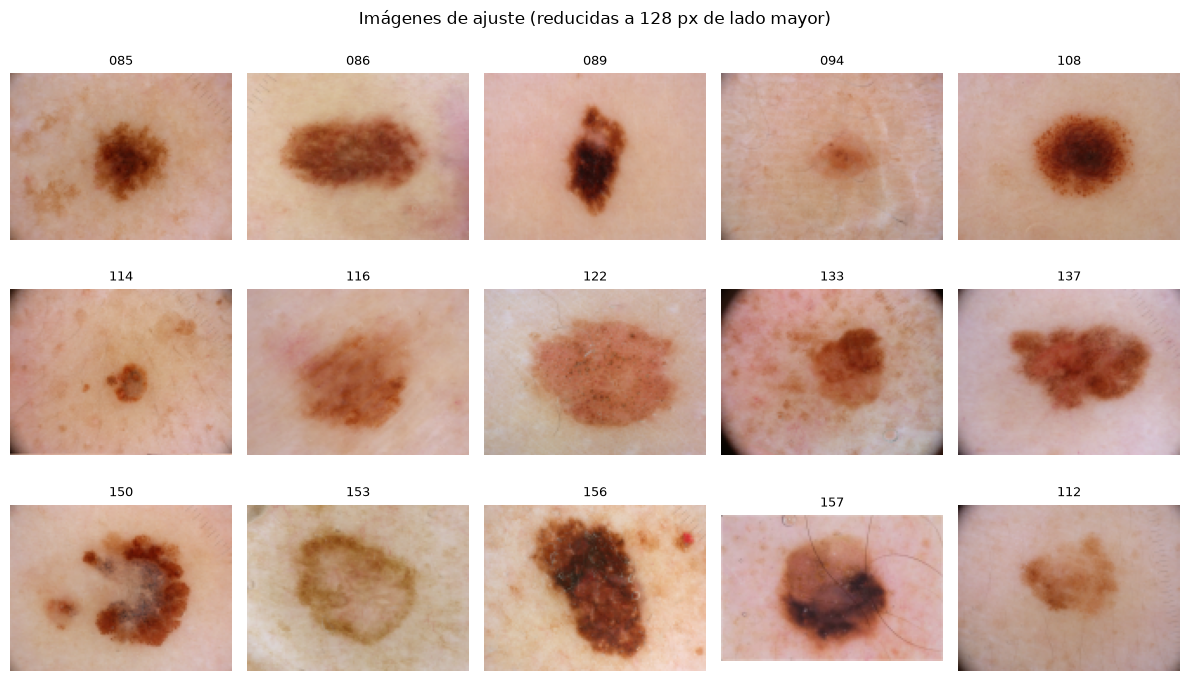

In [4]:
def abreviar(id_img):
    return id_img.replace('ISIC_0000', '')


def mostrar_imgs(dic_imgs, titulo, columnas=5):
    filas = int(np.ceil(len(dic_imgs) / columnas))
    fig, ejes = plt.subplots(filas, columnas, layout='tight', figsize=(12, 2.4 * filas))
    ejes = np.atleast_2d(ejes)
    for eje in ejes.ravel():
        eje.axis('off')
    for eje, (id_img, imagen) in zip(ejes.ravel(), dic_imgs.items()):
        eje.imshow(imagen)
        eje.set_title(abreviar(id_img), fontsize=9)
    plt.suptitle(titulo)
    plt.show()


mostrar_imgs(imagenes, 'Imágenes de ajuste (reducidas a 128 px de lado mayor)')

### 1.2 Preparación de las máscaras de referencia

Las máscaras contienen 0 (piel) y 255 (lesión). La función siguiente las convierte a 0 y 1 y las redimensiona con **interpolación por vecino más cercano** para conservar valores binarios y tener exactamente las mismas dimensiones que la imagen reducida. Se verifican la forma y los valores de las 15 máscaras de ajuste.

In [5]:
def cargar_mascara_referencia(id_img, forma_hw, carpeta=dir_mascaras):
    ruta = os.path.join(carpeta, f'{id_img}_Segmentation.png')
    mascara = cv2.imread(ruta, cv2.IMREAD_GRAYSCALE)
    if mascara is None:
        raise FileNotFoundError(ruta)
    alto, ancho = forma_hw
    mascara = cv2.resize(mascara, (ancho, alto), interpolation=cv2.INTER_NEAREST)
    return (mascara > 127).astype(np.uint8)


mascaras_ref = {id_img: cargar_mascara_referencia(id_img, imagenes[id_img].shape[:2]) for id_img in ids_ajuste}

for id_img in ids_ajuste:
    assert mascaras_ref[id_img].shape == imagenes[id_img].shape[:2]
    assert set(np.unique(mascaras_ref[id_img])) <= {0, 1}

area_ref = pd.Series({abreviar(i): m.mean() for i, m in mascaras_ref.items()}, name='fracción de lesión')
print(f'{len(mascaras_ref)} máscaras cargadas. Fracción de la imagen ocupada por la lesión: '
      f'mín {area_ref.min():.3f}, media {area_ref.mean():.3f}, máx {area_ref.max():.3f}')
area_ref.round(3).to_frame().T

15 máscaras cargadas. Fracción de la imagen ocupada por la lesión: mín 0.031, media 0.223, máx 0.391


,085,086,089,094,108,114,116,122,133,137,150,153,156,157,112
fracción de lesión,0.127,0.234,0.121,0.059,0.185,0.031,0.361,0.391,0.142,0.244,0.323,0.277,0.314,0.331,0.202


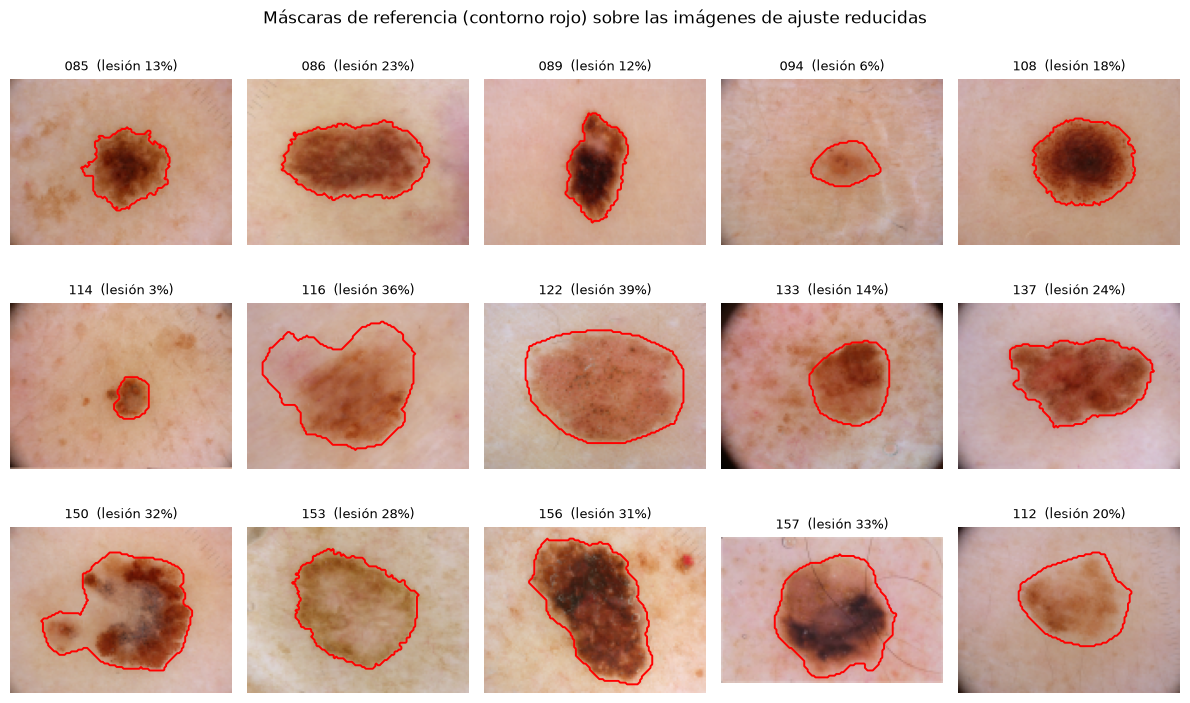

In [6]:
fig, ejes = plt.subplots(3, 5, layout='tight', figsize=(12, 7.5))
for eje, id_img in zip(ejes.ravel(), ids_ajuste):
    eje.imshow(imagenes[id_img])
    eje.contour(mascaras_ref[id_img], levels=[0.5], colors='red', linewidths=1.4)
    eje.set_title(f'{abreviar(id_img)}  (lesión {mascaras_ref[id_img].mean():.0%})', fontsize=9)
    eje.axis('off')
plt.suptitle('Máscaras de referencia (contorno rojo) sobre las imágenes de ajuste reducidas')
plt.show()

### 1.3 Representación de cada píxel y pipeline de Scikit-learn

Cada imagen se convierte en una matriz con **un píxel por fila**, las características con R, G, B divididos por 255 y las coordenadas x (columna) e y (fila) divididas por (W − 1) y (H − 1), siendo **W** el ancho y **H** el alto de la imagen, de modo que todo queda en [0, 1] antes de ponderar. Decisiones de diseño:

- **Transformador propio** (CaracteristicasPixel): Scikit-learn no trae un transformador que convierta una imagen en píxeles con coordenadas, por lo que no hay fuga de información entre imágenes.
- **No se usa `StandardScaler`**: estandarizar cada columna alteraría la escala relativa color/posición, que es justamente lo que controlan los hiperparámetros β y λ. La normalización a [0, 1] ya hace comparables ambas fuentes de información.

In [11]:
class CaracteristicasPixel(BaseEstimator, TransformerMixin):
    def __init__(self, beta=1.0, lam=0.0):
        self.beta = beta
        self.lam = lam

    def fit(self, imagen, y=None):
        return self

    def transform(self, imagen):
        if self.beta < 0 or self.lam < 0 or (self.beta == 0 and self.lam == 0):
            raise ValueError('beta y lam deben ser >= 0 y no ambos cero.')
        imagen = np.asarray(imagen)
        alto, ancho, _ = imagen.shape
        rgb = imagen.reshape(-1, 3).astype(np.float64) / 255.0
        filas, columnas = np.meshgrid(np.arange(alto), np.arange(ancho), indexing='ij')
        x = columnas.ravel() / (ancho - 1)
        y = filas.ravel() / (alto - 1)
        return np.column_stack([self.beta * rgb, self.lam * x, self.lam * y])


def construir_pipeline(beta=1.0, lam=0.0, k=3, sem=semilla):
    return Pipeline([
        ('pixeles', CaracteristicasPixel(beta=beta, lam=lam)),
        ('kmeans', KMeans(n_clusters=k, n_init=3, random_state=sem)),
    ])

In [12]:
# Verificación del transformador sobre una imagen
pipeline = construir_pipeline()
imagen_0 = imagenes['ISIC_0000085']
columnas = ['beta*R', 'beta*G', 'beta*B', 'lam*x', 'lam*y']

maximos = []
for nombre, (beta, lam) in {'color + posición (1, 1)': (1, 1), 'pesos (0.5, 2)': (0.5, 2),
                            'solo color (1, 0)': (1, 0), 'solo posición (0, 1)': (0, 1)}.items():
    pipeline.set_params(pixeles__beta=beta, pixeles__lam=lam)
    matriz = pipeline.named_steps['pixeles'].transform(imagen_0)
    assert matriz.shape == (imagen_0.shape[0] * imagen_0.shape[1], 5)
    maximos.append(pd.Series(matriz.max(axis=0), index=columnas, name=nombre))
    if lam == 0: assert np.all(matriz[:, 3:] == 0)
    if beta == 0: assert np.all(matriz[:, :3] == 0)

print(f'Imagen {abreviar("ISIC_0000085")}: {imagen_0.shape[0]} x {imagen_0.shape[1]} = {len(matriz)} píxeles, matriz de {matriz.shape[0]} x {matriz.shape[1]}')
pd.DataFrame(maximos).round(3)

Imagen 085: 96 x 128 = 12288 píxeles, matriz de 12288 x 5


,beta*R,beta*G,beta*B,lam*x,lam*y
"color + posición (1, 1)",0.839,0.714,0.710,1.0,1.0
"pesos (0.5, 2)",0.420,0.357,0.355,2.0,2.0
"solo color (1, 0)",0.839,0.714,0.710,0.0,0.0
"solo posición (0, 1)",0.000,0.000,0.000,1.0,1.0


Las verificaciones confirman la forma (H·W) × 5, que con β = λ = 1 las columnas máximas no superan 1 (los máximos de color son < 1 porque estas imágenes no saturan los canales), y que los casos extremos anulan las columnas correspondientes. Ahora se muestra que **el mismo pipeline** produce agrupaciones muy distintas cambiando solo β, λ y K:

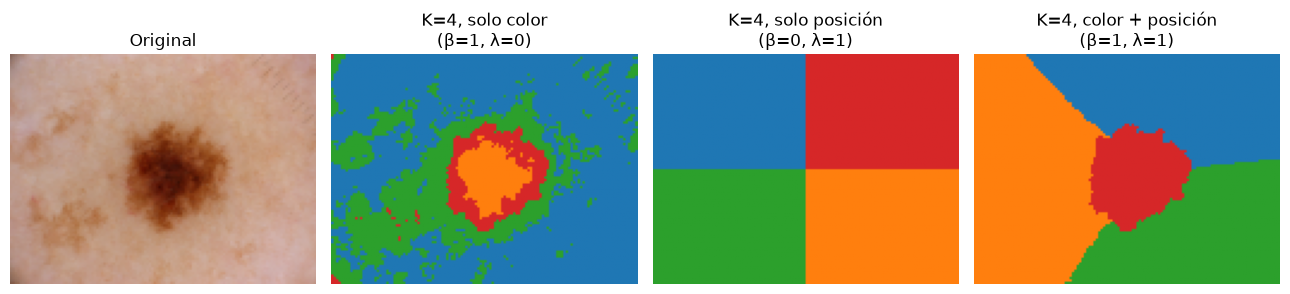

In [ ]:
configuraciones = {'solo color\n(β=1, λ=0)': (1, 0), 'solo posición\n(β=0, λ=1)': (0, 1),
                   'color + posición\n(β=1, λ=1)': (1, 1)}

fig, ejes = plt.subplots(1, 4, layout='tight', figsize=(13, 3.2))
ejes[0].imshow(imagen_0)
ejes[0].set_title('Original')
for eje, (nombre, (beta, lam)) in zip(ejes[1:], configuraciones.items()):
    pipeline = construir_pipeline().set_params(pixeles__beta=beta, pixeles__lam=lam, kmeans__n_clusters=4)
    etiquetas = pipeline.fit_predict(imagen_0).reshape(imagen_0.shape[:2])
    eje.imshow(etiquetas, cmap='tab10', vmin=0, vmax=9)
    eje.set_title(f'K=4, {nombre}')
for eje in ejes:
    eje.axis('off')
plt.show()

Con solo color los grupos corresponden a zonas de tono parecido sin importar dónde estén, con solo posición se obtiene una partición geométrica independiente de la imagen, con ambos, los grupos son tonalmente homogéneos y compactos.

## 2. Agrupación y selección de K

### 2.1 Diez combinaciones de (β, λ)

K-medias usa distancias euclídeas, así que **multiplicar β y λ por la misma constante no cambia los grupos**. Lo único que importa es la razón λ/β. Por eso se fija β = 1 y se varía λ con ocho razones distintas, más los dos extremos: solo color (λ = 0) y solo posición (β = 0).

In [14]:
razones = [0.1, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 4.0]
combinaciones = [(1.0, 0.0)] + [(1.0, r) for r in razones] + [(0.0, 1.0)]

def nombre_combinacion(beta, lam):
    if lam == 0:
        return 'solo color'
    if beta == 0:
        return 'solo posición'
    return f'λ/β={lam / beta:g}'


nombres_comb = [nombre_combinacion(beta, lam) for beta, lam in combinaciones]
pd.DataFrame({'beta': [beta for beta, _ in combinaciones], 'lam': [lam for _, lam in combinaciones]},
             index=nombres_comb)

,beta,lam
solo color,1.0,0.00
λ/β=0.1,1.0,0.10
λ/β=0.25,1.0,0.25
λ/β=0.5,1.0,0.50
λ/β=0.75,1.0,0.75
λ/β=1,1.0,1.00
λ/β=1.5,1.0,1.50
λ/β=2,1.0,2.00
λ/β=4,1.0,4.00
solo posición,0.0,1.00


In [ ]:
def indices_muestra_silueta(n_pixeles, tamano=n_muestra, sem=semilla):
    return np.random.default_rng(sem).choice(n_pixeles, size=min(tamano, n_pixeles), replace=False)


def explorar_imagen(id_img, imagen, combs=combinaciones, valores_k=rango_k):
    indices = indices_muestra_silueta(imagen.shape[0] * imagen.shape[1])
    pipeline = construir_pipeline()
    registros, mejores = [], {}
    for beta, lam in combs:
        pipeline.set_params(pixeles__beta=beta, pixeles__lam=lam)
        matriz = pipeline.named_steps['pixeles'].transform(imagen)
        mejor = (-np.inf, None, None)   # (silueta, k, etiquetas)
        for k in valores_k:
            pipeline.set_params(kmeans__n_clusters=k)
            etiquetas = pipeline.fit_predict(imagen)
            hay_dos_grupos = len(np.unique(etiquetas[indices])) > 1
            silueta = silhouette_score(matriz[indices], etiquetas[indices]) if hay_dos_grupos else np.nan
            registros.append(dict(imagen=id_img, combo=nombre_combinacion(beta, lam), beta=beta, lam=lam,
                                  k=k, silueta=silueta))
            if silueta > mejor[0]:
                mejor = (silueta, k, etiquetas.reshape(imagen.shape[:2]))
        mejores[(id_img, nombre_combinacion(beta, lam))] = dict(k=mejor[1], silueta=mejor[0], etiquetas=mejor[2])
    return registros, mejores

### 2.2 Selección de K por coeficiente de silueta

Para cada imagen de ajuste y cada combinación se ajusta K-medias con K entre 2 y 8 y se elige el K de **mayor silueta**.

- **Tamaño de la muestra:** 2000 píxeles
- **Semilla:** 2026 (`np.random.default_rng(2026)`), muestreo sin reemplazo.
- Se usa **la misma muestra** para todos los K y combinaciones de una imagen, de modo que las comparaciones entre K sean limpias.
- K-medias: n_init=3, random_state=2026, no se usan máscaras de referencia.

In [28]:
inicio = time.time()
registros, mejores = [], {}
for id_img, imagen in imagenes.items():
    reg, mej = explorar_imagen(id_img, imagen)
    registros += reg
    mejores.update(mej)
resultados = pd.DataFrame(registros)
n_pix = imagenes[ids_ajuste[0]].shape[0] * imagenes[ids_ajuste[0]].shape[1]
print(f'{len(resultados)} ajustes de K-medias ({len(imagenes)} imágenes x {len(combinaciones)} combinaciones x {len(rango_k)} valores de K)')
print(f'Muestra para la silueta: {n_muestra} píxeles de {n_pix} por imagen, semilla = {semilla}')

1050 ajustes de K-medias (15 imágenes x 10 combinaciones x 7 valores de K)
Muestra para la silueta: 2000 píxeles de 12288 por imagen, semilla = 2026


### 2.3 Resultados

In [17]:
mejor_k = resultados.loc[resultados.groupby(['imagen', 'combo'])['silueta'].idxmax()]
tabla_k = mejor_k.pivot(index='imagen', columns='combo', values='k')[nombres_comb]
tabla_k.index = [abreviar(i) for i in tabla_k.index]
tabla_k.index.name = 'imagen'
tabla_k

combo,solo color,λ/β=0.1,λ/β=0.25,λ/β=0.5,λ/β=0.75,λ/β=1,λ/β=1.5,λ/β=2,λ/β=4,solo posición
imagen,,,,,,,,,,
085,2,2,2,2,5,5,5,5,5,4
086,2,2,2,2,5,5,5,5,5,4
089,2,2,2,2,5,5,5,5,5,4
094,2,2,5,5,5,5,5,4,4,4
108,2,2,2,2,5,5,5,5,5,4
112,2,2,2,5,5,5,5,5,4,4
114,2,2,2,5,5,5,4,4,4,4
116,2,2,2,5,5,5,5,5,5,4
122,2,2,2,5,5,5,5,5,5,4


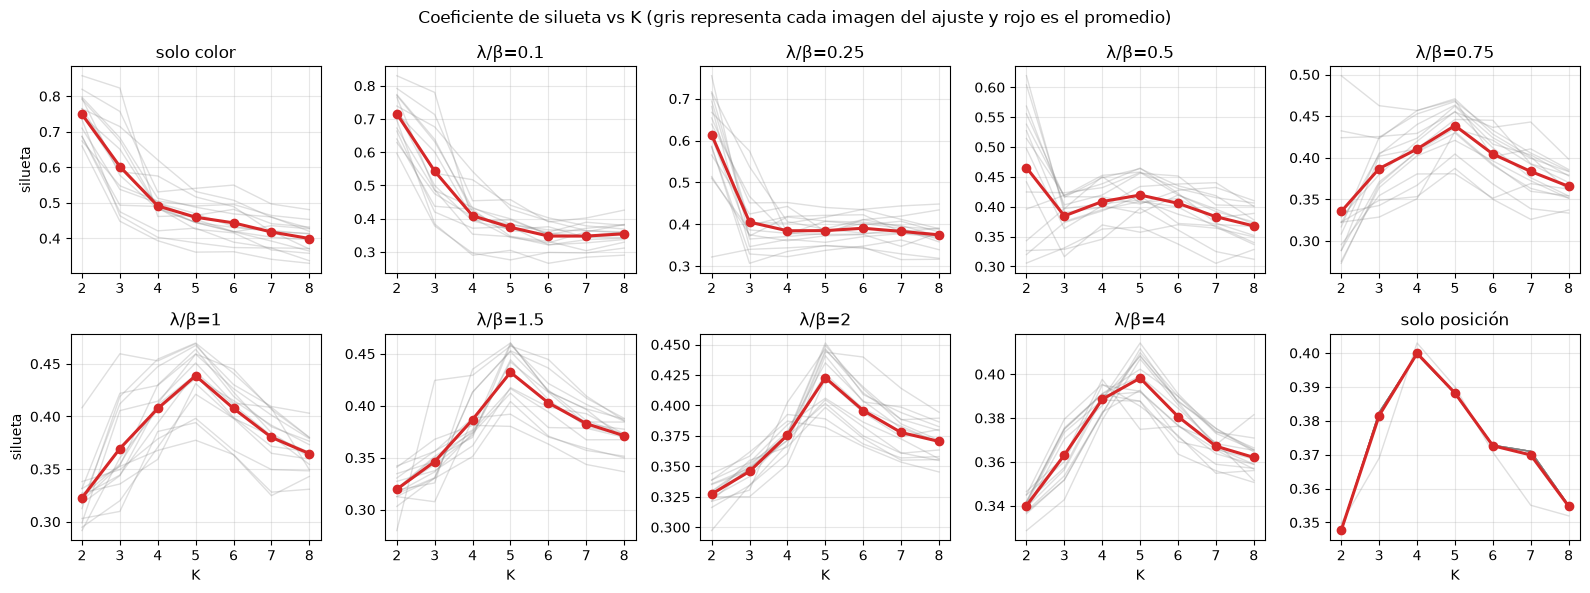

In [34]:
fig, ejes = plt.subplots(2, 5, layout='tight', figsize=(16, 6))
for eje, nombre in zip(ejes.ravel(), nombres_comb):
    sub = resultados[resultados.combo == nombre].pivot(index='k', columns='imagen', values='silueta')
    eje.plot(sub.index, sub.values, color='gray', alpha=0.25, lw=1)
    eje.plot(sub.index, sub.mean(axis=1), color='C3', lw=2.2, marker='o', label='promedio')
    eje.set_title(nombre)
    eje.set_xticks(list(rango_k))
    eje.grid(alpha=0.3)
for eje in ejes[1]:
    eje.set_xlabel('K')
for eje in ejes[:, 0]:
    eje.set_ylabel('silueta')
plt.suptitle('Coeficiente de silueta vs K (gris representa cada imagen del ajuste y rojo es el promedio)')
plt.show()

In [32]:
resumen = mejor_k.groupby('combo').agg(
    silueta_media=('silueta', 'mean'),
    k_mediana=('k', 'median'),
    k_moda=('k', lambda s: s.mode().iloc[0]),
    n_k2=('k', lambda s: int((s == 2).sum())),
    n_k_ge5=('k', lambda s: int((s >= 5).sum())),
).loc[nombres_comb].round(3)
resumen

,silueta_media,k_mediana,k_moda,n_k2,n_k_ge5
combo,,,,,
solo color,0.749,2.0,2,15,0
λ/β=0.1,0.716,2.0,2,15,0
λ/β=0.25,0.616,2.0,2,14,1
λ/β=0.5,0.492,2.0,2,9,6
λ/β=0.75,0.441,5.0,5,1,14
λ/β=1,0.439,5.0,5,0,15
λ/β=1.5,0.432,5.0,5,0,14
λ/β=2,0.423,5.0,5,0,13
λ/β=4,0.401,5.0,5,0,10


**Lectura de los resultados (15 imágenes de ajuste):**

- **Solo color y λ/β ≤ 0.25:** la silueta elige K = 2 en prácticamente todas las imágenes (15/15, 15/15 y 14/15). Es coherente con la estructura dominante de estas imágenes con las clase de lunar/lesiín y piel. La silueta media es la más alta (0.75 con solo color).
- **λ/β ≥ 0.75:** el K pasa a 5 en la mayoría (14, 15, 14, 13 y 10 de 15). Con mucho peso espacial, K-medias tiende a partir la imagen en regiones compactas, el patrón típico es *cuatro regiones de piel + un grupo central para la lesión*.
- **λ/β = 0.5** es un punto de transición (9 imágenes con K = 2 y 6 con K ≥ 5).
- **Solo posición:** K = 4 en las 15 imágenes y silueta 0.40. Es un resultado esperable, pues sin color la partición no depende del contenido, solo de la geometría.

## 3. Criterio de construcción de la máscara de la lesión

K-medias agrupa los píxeles pero **no dice cuál grupo es la lesión**. Se necesita un criterio automático que use solo las características de los grupos (color, tamaño, ubicación), sin hacer uso de máscaras de referencia.

### 3.1 Descriptores de cada grupo

Con base en cómo lucen las imágenes de ajuste, una lesión suele ser: 

**Más oscura o más pigmentada que la piel alrededor**

**Central** (las fotos están encuadradas sobre la lesión) 

**Un solo objeto compacto**. 

In [ ]:
def descriptores_grupos(imagen, etiquetas, fraccion_marco=0.10):
    alto, ancho, _ = imagen.shape
    rgb = imagen.reshape(-1, 3).astype(np.float64) / 255.0
    lum = rgb @ np.array([0.299, 0.587, 0.114])
    filas, columnas = np.meshgrid(np.arange(alto), np.arange(ancho), indexing='ij')
    x, y = columnas.ravel() / (ancho - 1), filas.ravel() / (alto - 1)
    grosor = max(1, round(fraccion_marco * min(alto, ancho)))
    marco = ((filas < grosor) | (filas >= alto - grosor) | (columnas < grosor) | (columnas >= ancho - grosor)).ravel()
    piel = np.median(rgb[marco], axis=0)
    etiq = etiquetas.ravel()

    datos = {}
    for grupo in np.unique(etiq):
        sel = etiq == grupo
        color_medio = rgb[sel].mean(axis=0)
        datos[grupo] = dict(
            tamano=sel.mean(),
            luminancia=lum[sel].mean(),
            contraste=np.linalg.norm(color_medio - piel),
            dist_centro=np.hypot(x[sel].mean() - 0.5, y[sel].mean() - 0.5) / np.hypot(0.5, 0.5),
            frac_borde=marco[sel].mean(),
        )
    tabla = pd.DataFrame(datos).T
    tabla.index.name = 'grupo'
    tabla['puntaje'] = tabla.contraste * (1 - tabla.dist_centro) * (1 - tabla.frac_borde)
    return tabla, piel

### 3.2 Dos criterios

**Criterio 1 – oscuro (solo color).** La lesión es el grupo de menor luminancia media. No tiene parámetros y sirve de referencia. Falla cuando hay algo más oscuro que la lesión como pelos y, como trabaja a nivel de grupo, hereda las motas sueltas que K-medias agrupe con la lesión.

**Criterio 2 – puntaje (color + ubicación + forma).**

1. Se calcula para cada grupo $\text{puntaje} = \text{contraste} \times (1-\text{dist\_centro}) \times (1-\text{frac\_borde})$.
2. Se eligen los grupos con puntaje ≥ τ · (mejor puntaje), con τ = 0.5, porque con K grande la lesión puede repartirse en varios grupos.
3. De la unión de esos grupos se conserva el **componente conexo más grande** y se rellenan sus huecos. Elimina motas y esquinas, y cierra zonas claras en el interior de la lesión.

El contraste se mide contra el marco exterior y no contra la mediana de toda la imagen, porque una lesión grande puede ocupar más de la mitad de la imagen, mientras que el marco casi siempre es piel.

In [ ]:
from scipy import ndimage


def mascara_mas_oscuro(imagen, etiquetas):
    """Criterio 1 (solo color)"""
    tabla, _ = descriptores_grupos(imagen, etiquetas)
    elegidos = [tabla.luminancia.idxmin()]
    return np.isin(etiquetas, elegidos).astype(np.uint8), elegidos


def mayor_componente_rellena(mascara):
    componentes, n_comp = ndimage.label(mascara, structure=np.ones((3, 3)))
    if n_comp == 0:
        return mascara
    tamanos = np.bincount(componentes.ravel())[1:]
    principal = componentes == (np.argmax(tamanos) + 1)
    return ndimage.binary_fill_holes(principal).astype(np.uint8)

tau = 0.5
def mascara_puntaje(imagen, etiquetas, umbral_rel=tau, limpiar=True):
    """Criterio 2"""
    tabla, _ = descriptores_grupos(imagen, etiquetas)
    elegidos = tabla.index[tabla.puntaje >= umbral_rel * tabla.puntaje.max()].tolist()
    mascara = np.isin(etiquetas, elegidos).astype(np.uint8)
    if limpiar:
        mascara = mayor_componente_rellena(mascara)
    return mascara, elegidos


criterios = {'oscuro': mascara_mas_oscuro, 'puntaje': mascara_puntaje}

In [ ]:
ejemplo = mejores[('ISIC_0000085', 'λ/β=0.5')]
tabla_desc, piel = descriptores_grupos(imagenes['ISIC_0000085'], ejemplo['etiquetas'])
print(f"K elegido por silueta: {ejemplo['k']}, color de piel de referencia (RGB en [0,1]): {np.round(piel, 2)}")
_, elegido_1 = mascara_mas_oscuro(imagenes['ISIC_0000085'], ejemplo['etiquetas'])
_, elegido_2 = mascara_puntaje(imagenes['ISIC_0000085'], ejemplo['etiquetas'])
print(f'Grupo(s) elegido(s) -> criterio "oscuro": {elegido_1}   criterio "puntaje": {elegido_2}')
tabla_desc.round(3)

K elegido por silueta: 2, color de piel de referencia (RGB en [0,1]): [0.78 0.62 0.56]
Grupo(s) elegido(s) -> criterio "oscuro": [0]   criterio "puntaje": [0]


,tamano,luminancia,contraste,dist_centro,frac_borde,puntaje
grupo,,,,,,
0,0.106,0.316,0.629,0.058,0.006,0.589
1,0.894,0.646,0.040,0.007,0.371,0.025


Ejemplo de descriptores en la imagen 085: el grupo 0 (lunar) tiene contraste alto, está cerca del centro y casi no toca el borde; Por el otro lado, el grupo 1 (piel) está perfectamente centrado  pero su contraste es muy bajo, además el 37 % de sus píxeles están en el marco. Ambos criterios eligen el grupo 0.

### 3.3 Aplicación a las 15 imágenes × 10 combinaciones

Aquí se hacen chequeos **sin comparar contra las máscaras**. Además, una adaptación del criterio 2, con y sin el paso de limpieza.

In [36]:
from functools import partial

variantes = {'oscuro': mascara_mas_oscuro,
             'puntaje sin limpieza': partial(mascara_puntaje, limpiar=False),
             'puntaje': mascara_puntaje}

filas, mascaras = [], {}
for (id_img, combo), mejor in mejores.items():
    for nombre, criterio in variantes.items():
        mascara, elegidos = criterio(imagenes[id_img], mejor['etiquetas'])
        mascaras[(id_img, combo, nombre)] = mascara
        n_comp = ndimage.label(mascara, structure=np.ones((3, 3)))[1]
        filas.append(dict(imagen=id_img, combo=combo, variante=nombre, area=mascara.mean(), n_comp=n_comp, k=mejor['k']))
diagnostico = pd.DataFrame(filas)

diagnostico['degenerada'] = (diagnostico.area < 0.02) | (diagnostico.area > 0.80)
tabla1 = diagnostico[diagnostico.variante != 'puntaje sin limpieza'].pivot_table(
    index='combo', columns='variante', values=['area', 'degenerada']).loc[nombres_comb]
tabla1.columns = [f'{medida} ({variante})' for medida, variante in tabla1.columns]
tabla1 = tabla1.rename(columns={'area (oscuro)': 'área media (oscuro)', 'area (puntaje)': 'área media (puntaje)',
                                'degenerada (oscuro)': '% degeneradas (oscuro)',
                                'degenerada (puntaje)': '% degeneradas (puntaje)'})
tabla1[['% degeneradas (oscuro)', '% degeneradas (puntaje)']] *= 100
print(f'Referencia: la lesión ocupa entre {area_ref.min():.0%} y {area_ref.max():.0%} de la imagen (media {area_ref.mean():.0%}) en las 15 imágenes de ajuste.')
tabla1.round(2)

Referencia: la lesión ocupa entre 3% y 39% de la imagen (media 22%) en las 15 imágenes de ajuste.


,área media (oscuro),área media (puntaje),% degeneradas (oscuro),% degeneradas (puntaje)
combo,,,,
solo color,0.19,0.18,0.0,0.00
λ/β=0.1,0.19,0.18,0.0,0.00
λ/β=0.25,0.19,0.18,0.0,0.00
λ/β=0.5,0.18,0.18,0.0,0.00
λ/β=0.75,0.18,0.18,0.0,0.00
λ/β=1,0.18,0.18,0.0,0.00
λ/β=1.5,0.19,0.19,0.0,0.00
λ/β=2,0.19,0.24,0.0,6.67
λ/β=4,0.20,0.35,0.0,6.67


In [37]:
def iou(a, b):
    union = np.logical_or(a, b).sum()
    return np.logical_and(a, b).sum() / union if union else 1.0


tabla2 = diagnostico.pivot_table(index='combo', columns='variante', values='n_comp').loc[nombres_comb]
tabla2 = tabla2[['oscuro', 'puntaje sin limpieza', 'puntaje']]
tabla2.columns = [f'componentes ({c})' for c in tabla2.columns]
for variante, columna in [('puntaje sin limpieza', 'IoU oscuro vs puntaje sin limpieza'),
                          ('puntaje', 'IoU oscuro vs puntaje')]:
    tabla2[columna] = pd.Series({c: np.mean([iou(mascaras[(i, c, 'oscuro')], mascaras[(i, c, variante)])
                                             for i in ids_ajuste]) for c in nombres_comb})
tabla2.round(2)

,componentes (oscuro),componentes (puntaje sin limpieza),componentes (puntaje),IoU oscuro vs puntaje sin limpieza,IoU oscuro vs puntaje
combo,,,,,
solo color,7.73,7.73,1.0,1.00,0.91
λ/β=0.1,8.13,8.13,1.0,1.00,0.91
λ/β=0.25,6.20,6.20,1.0,1.00,0.92
λ/β=0.5,5.73,5.73,1.0,1.00,0.94
λ/β=0.75,4.73,4.73,1.0,1.00,0.97
λ/β=1,3.33,3.33,1.0,1.00,0.99
λ/β=1.5,2.40,2.40,1.0,1.00,1.00
λ/β=2,1.40,1.40,1.0,0.95,0.95
λ/β=4,1.00,1.00,1.0,0.82,0.82


**Qué muestran los chequeos:**

- **Con color dominante (λ/β ≤ 1.5)** ambos criterios dan áreas similares y ninguna máscara degenerada.
- **Con λ/β ≥ 2 el criterio 2 se infla** (área media 0.24 y 0.35) porque los grupos son regiones espaciales que mezclan lesión y piel, y al unir los de puntaje similar se agrega piel. Con **solo posición** la máscara es arbitraria (área media 0.73, 13 % degeneradas), sin color no hay forma de distinguir lesión de piel.
- **Adaptación limpieza.** La selección por puntaje sin limpieza produce exactamente las mismas máscaras que el grupo más oscuro mientras λ/β ≤ 1.5. En estas imágenes el grupo de mayor contraste es también el más oscuro. **La mejora real del criterio 2 viene del paso de limpieza**, pues el criterio 1 deja en promedio 7–8 componentes conexas con color dominante (motas, esquinas), y el criterio 2 deja siempre 1.

### 3.4 Visualización de los grupos y las máscaras

Ahora, vamos a proceder a comparar las mascaras originales, con la adpatación de ambos criterios, y probar desde un punto de vista visual, el desempeño de ambos al momento de la agrupación.

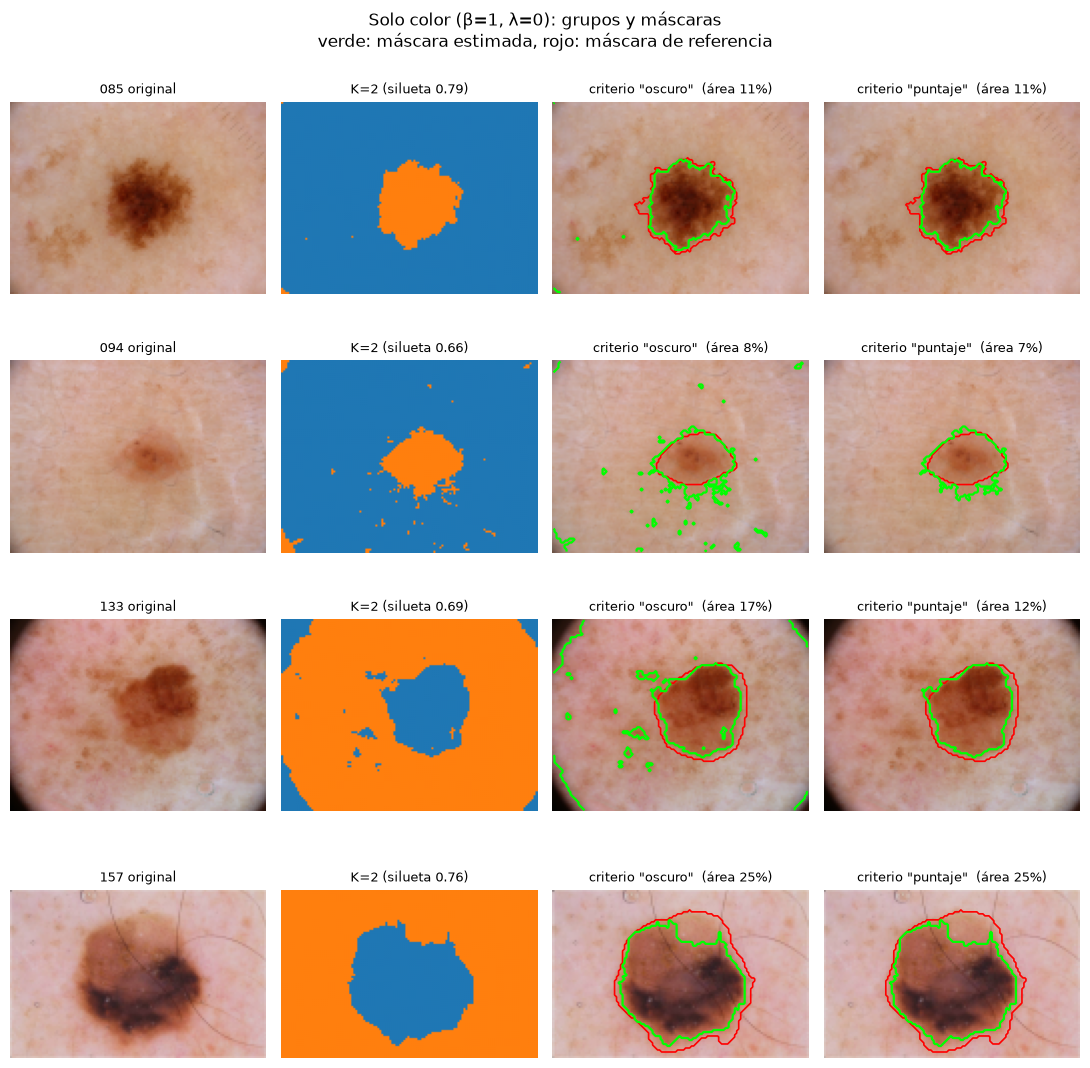

In [38]:
def mostrar_mascaras(combo, ids, titulo):
    fig, ejes = plt.subplots(len(ids), 4, layout='tight', figsize=(11, 2.7 * len(ids) + 0.6))
    for fila, id_img in enumerate(ids):
        mejor = mejores[(id_img, combo)]
        ejes[fila, 0].imshow(imagenes[id_img])
        ejes[fila, 0].set_title(f'{abreviar(id_img)} original', fontsize=9)
        ejes[fila, 1].imshow(mejor['etiquetas'], cmap='tab10', vmin=0, vmax=9)
        ejes[fila, 1].set_title(f"K={mejor['k']} (silueta {mejor['silueta']:.2f})", fontsize=9)
        for col, nombre in enumerate(criterios, start=2):
            mascara = mascaras[(id_img, combo, nombre)]
            ejes[fila, col].imshow(imagenes[id_img])
            ejes[fila, col].contour(mascaras_ref[id_img], levels=[0.5], colors='red', linewidths=1.2)
            ejes[fila, col].contour(mascara, levels=[0.5], colors='lime', linewidths=1.6)
            ejes[fila, col].set_title(f'criterio "{nombre}"  (área {mascara.mean():.0%})', fontsize=9)
    for eje in ejes.ravel():
        eje.axis('off')
    plt.suptitle(titulo + '\nverde: máscara estimada, rojo: máscara de referencia')
    plt.show()


ejemplos = ['ISIC_0000085', 'ISIC_0000094', 'ISIC_0000133', 'ISIC_0000157']
mostrar_mascaras('solo color', ejemplos, 'Solo color (β=1, λ=0): grupos y máscaras')

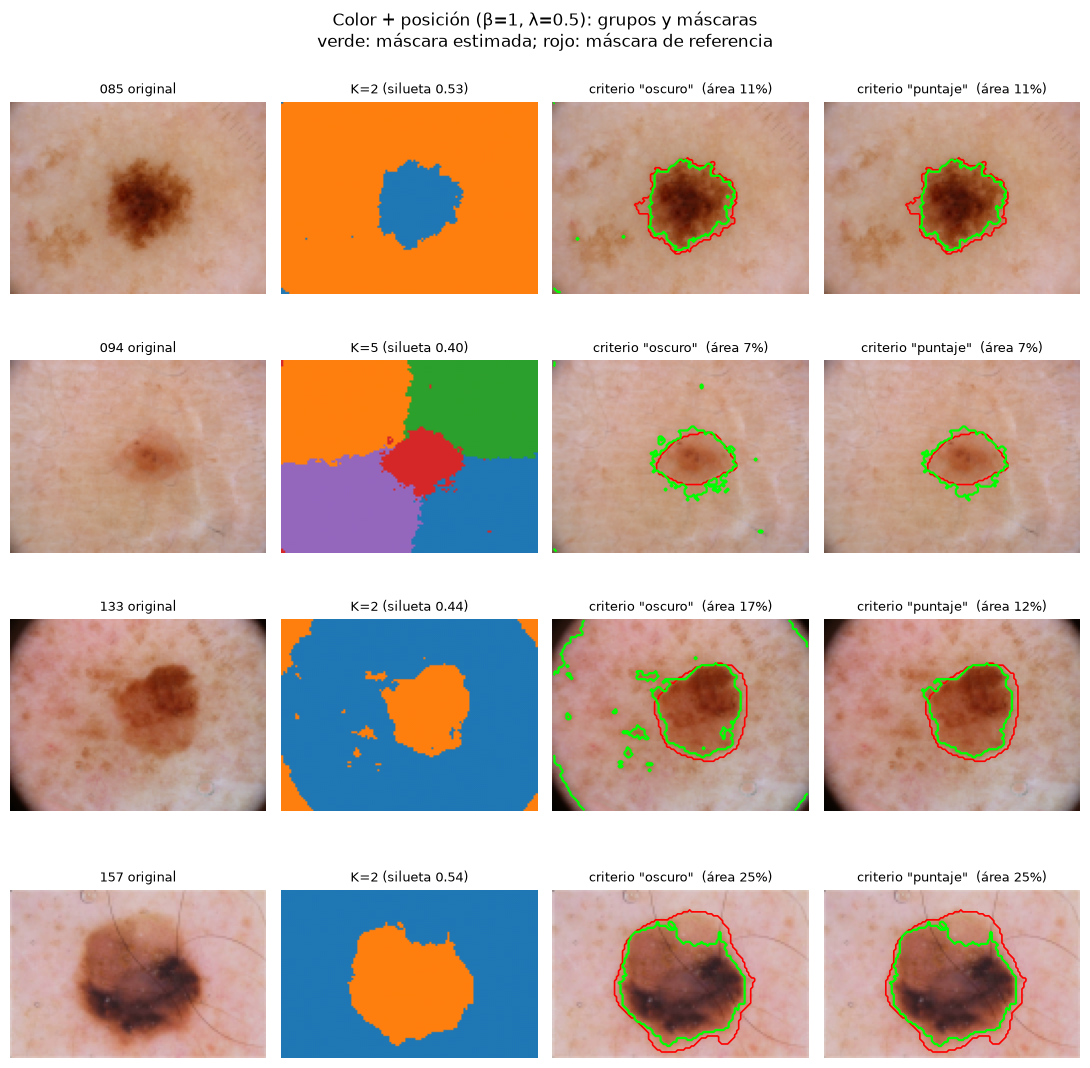

In [27]:
mostrar_mascaras('λ/β=0.5', ejemplos, 'Color + posición (β=1, λ=0.5): grupos y máscaras')

**Conclusiones de la inspección visual (solo imágenes de ajuste, comparando con las referencias):**

- En la **133**, con K = 2 la lesión y el viñeteado negro de las esquinas caen en el mismo grupo, el criterio 1 los incluye a ambos, y el criterio 2 elimina las esquinas al quedarse con la componente más grande, con un contorno muy cercano a la referencia.
- En la **094** (lesión de bajo contraste) el criterio 1 deja motas dispersas por la piel, mientras el criterio 2 las elimina, aunque queda un borde irregular en la parte inferior.
- En la **085** y la **157** las máscaras estimadas son **más pequeñas que la referencia**, dejan fuera la periferia más clara que los anotadores sí incluyeron. Con solo color y K = 2 el grupo *oscuro* no alcanza a cubrir esas zonas.
- En la **094** con λ/β ≥ 1 los grupos son tan compactos que la máscara se expande más allá de la lesión, creando una sobresegmentación.

## Uso de herramientas de IA generativa

### Declaración del uso

- **Herramienta:** Claude (Anthropic), modelo Claude Sonnet 5.5, a través de la interfaz de chat.
- **Tipo de uso:** generación inicial de código para la **carga y lectura de las imágenes y de las máscaras de referencia**, y para **combinar las máscaras con las imágenes reales** en las visualizaciones (contornos de las máscaras superpuestos sobre cada imagen).

### Prompts utilizados

| # | Prompt | Qué produjo y dónde se usa |
|:-:|:---|:---|
| 1 | "Ayúdame a crear funciones para cargar las imágenes." | `cargar_imagen` y `cargar_mascara_referencia` (secciones 1.1 y 1.2): lectura de las imágenes en RGB y de las máscaras, que se convierten de 0/255 a 0/1. |
| 2 | "Ayúdame a crear funciones para poder visualizar las máscaras dentro de las imágenes reales." | Figura de la sección 1.2: contorno de la máscara de referencia dibujado sobre cada imagen de ajuste, con el porcentaje de lesión en el título. |
| 3 | "Normaliza las imágenes a 128 píxeles." | `forma_reducida` y el parámetro `lado_max = 128`: el lado mayor de cada imagen se reduce a 128 píxeles conservando la proporción, con interpolación por área para las imágenes y por vecino más cercano para las máscaras. |
| 4 | "Crea una función para mostrar las máscaras de cada criterio, el de oscuro y el de puntaje." | `mostrar_mascaras` (sección 3.4): para cada imagen muestra el original, los grupos de K-medias y la máscara estimada de cada criterio, con la máscara de referencia superpuesta. |

### Análisis crítico del resultado

- **Partes correctas y útiles.** Las funciones de carga cumplieron lo que pide el enunciado para las máscaras: pasan de 0/255 a 0/1 y, al redimensionarse con vecino más cercano, conservan valores binarios. Esto se comprobó en el notebook con verificaciones de forma (misma que la imagen reducida) y de valores (solo 0 y 1), y visualmente los contornos de referencia coinciden con la lesión en las 15 imágenes de ajuste.
- **Errores, imprecisiones y limitaciones.**
  - La instrucción "normaliza a 128 píxeles" admite varias lecturas (reescalar los valores, o forzar un tamaño fijo de 128 × 128). Se interpretó como reducir el lado mayor a 128 píxeles conservando la proporción. Esta reducción pierde detalles finos (pelos, puntos pequeños), lo que se tiene en cuenta al interpretar los resultados.

### Aportes propios de los integrantes

- Se definieron los prompts que se utilizaron, la generación del pipeline también corrió por parte del grupo. Además de la propocición de ambos criterios para las creaciones de las mascaras. Adicionalmente, todos los análisis entregados sobre los resultados de la siueta de cada combinación y de cada criteior también fueron aportes de los integrantes.